Upload file kaggle.json kamu...


Saving kaggle.json to kaggle.json
Kaggle API berhasil dikonfigurasi!

Download berhasil!

        HASIL FILTER DATASET
BIOLOGICAL     : 997 gambar
PAPER          : 1,680 gambar
PLASTIC        : 1,984 gambar
---------------------------------------------
TOTAL          : 4,661 gambar

Lokasi dataset: /content/garbage_dataset


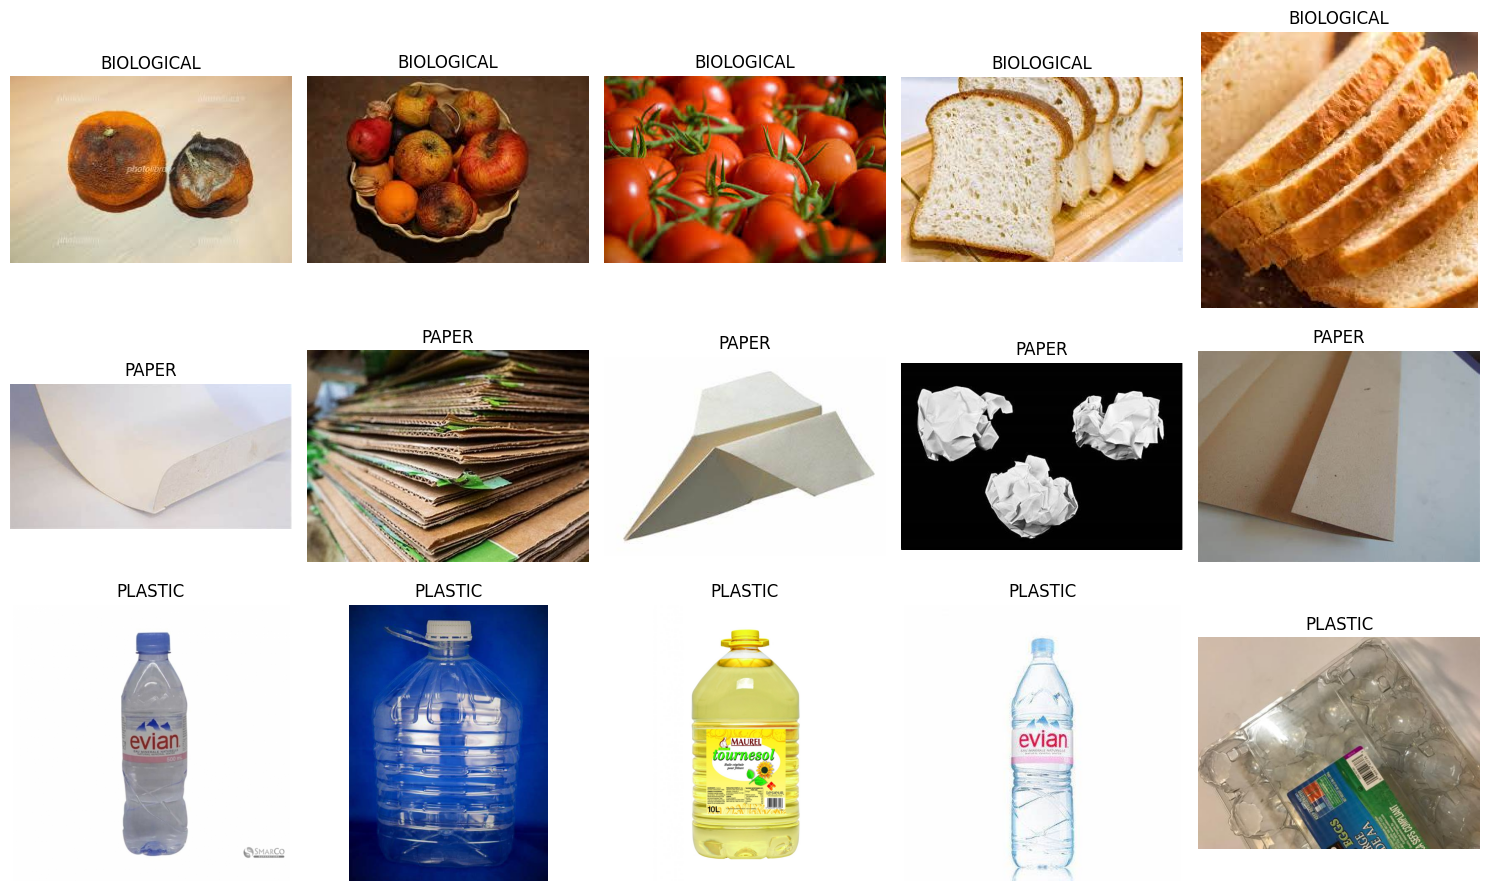


SEMUA PROSES SELESAI!


In [4]:

# ============================================
# 1. INSTALL KAGGLE
# ============================================
import sys
import subprocess
import os
import json
import shutil
import random
from pathlib import Path
from collections import Counter

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "kaggle"
])

# ============================================
# 2. UPLOAD KAGGLE API CREDENTIALS
# ============================================
from google.colab import files

print("Upload file kaggle.json kamu...")
uploaded = files.upload()

if "kaggle.json" not in uploaded:
    raise FileNotFoundError("File kaggle.json tidak ditemukan!")

kaggle_dir = Path("/root/.kaggle")
kaggle_dir.mkdir(parents=True, exist_ok=True)

kaggle_json = kaggle_dir / "kaggle.json"
kaggle_json.write_bytes(uploaded["kaggle.json"])

os.chmod(kaggle_json, 0o600)

print("Kaggle API berhasil dikonfigurasi!")

# ============================================
# 3. DOWNLOAD DATASET KAGGLE VERSI 8
# ============================================
dataset_raw = Path("/content/kaggle_raw")
dataset_raw.mkdir(parents=True, exist_ok=True)

print("\nDownloading Garbage Classification V2...")

subprocess.check_call([
    "kaggle", "datasets", "download",
    "sumn2u/garbage-classification-v2/8",
    "-p", str(dataset_raw),
    "--unzip"
])

print("Download berhasil!")

# ============================================
# 4. FILTER 3 KATEGORI
# ============================================
categories = ["biological", "paper", "plastic"]

output_path = Path("/content/garbage_dataset")

if output_path.exists():
    shutil.rmtree(output_path)

for category in categories:
    (output_path / category).mkdir(parents=True, exist_ok=True)

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

image_counts = Counter()

for image_path in dataset_raw.rglob("*"):

    if not image_path.is_file():
        continue

    if image_path.suffix.lower() not in image_extensions:
        continue

    # Cari folder kategori dari lokasi gambar
    category = next(
        (
            part.lower()
            for part in reversed(image_path.relative_to(dataset_raw).parts[:-1])
            if part.lower() in categories
        ),
        None
    )

    if category is None:
        continue

    destination = output_path / category / image_path.name

    # Hindari nama file yang sama
    counter = 1
    while destination.exists():
        destination = (
            output_path / category /
            f"{image_path.stem}_{counter}{image_path.suffix}"
        )
        counter += 1

    shutil.copy2(image_path, destination)
    image_counts[category] += 1

# ============================================
# 5. TAMPILKAN HASIL DATASET
# ============================================
print("\n" + "=" * 45)
print("        HASIL FILTER DATASET")
print("=" * 45)

total_images = 0

for category in categories:
    count = image_counts[category]
    total_images += count

    print(f"{category.upper():15}: {count:,} gambar")

print("-" * 45)
print(f"{'TOTAL':15}: {total_images:,} gambar")
print("=" * 45)

if total_images == 0:
    raise ValueError(
        "Tidak ditemukan gambar. Periksa kembali struktur dataset."
    )

print("\nLokasi dataset:", output_path)

# ============================================
# 6. VISUALISASI SAMPEL GAMBAR
# ============================================
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for row, category in enumerate(categories):

    category_images = list((output_path / category).glob("*"))

    samples = random.sample(
        category_images,
        min(5, len(category_images))
    )

    for col in range(5):
        ax = axes[row, col]
        ax.axis("off")

        if col < len(samples):
            img = Image.open(samples[col]).convert("RGB")
            ax.imshow(img)
            ax.set_title(category.upper())

plt.tight_layout()
plt.show()

print("\nSEMUA PROSES SELESAI!")


In [5]:
import os

DATASET_DIR = "/content/garbage_dataset"

for folder in os.listdir(DATASET_DIR):
    folder_path = os.path.join(DATASET_DIR, folder)

    if os.path.isdir(folder_path):
        print(folder, "->", len(os.listdir(folder_path)), "file")

plastic -> 1984 file
biological -> 997 file
paper -> 1680 file


In [6]:
from PIL import Image
import os

classes = ["biological", "paper", "plastic"]

for class_name in classes:
    folder_path = os.path.join(DATASET_DIR, class_name)
    valid_images = 0
    invalid_images = 0

    for filename in os.listdir(folder_path):
        file_path = os.path.join(folder_path, filename)

        try:
            with Image.open(file_path) as img:
                img.verify()
            valid_images += 1
        except Exception:
            invalid_images += 1

    print(
        f"{class_name}: "
        f"{valid_images} gambar valid, "
        f"{invalid_images} gambar bermasalah"
    )

biological: 997 gambar valid, 0 gambar bermasalah
paper: 1680 gambar valid, 0 gambar bermasalah
plastic: 1984 gambar valid, 0 gambar bermasalah


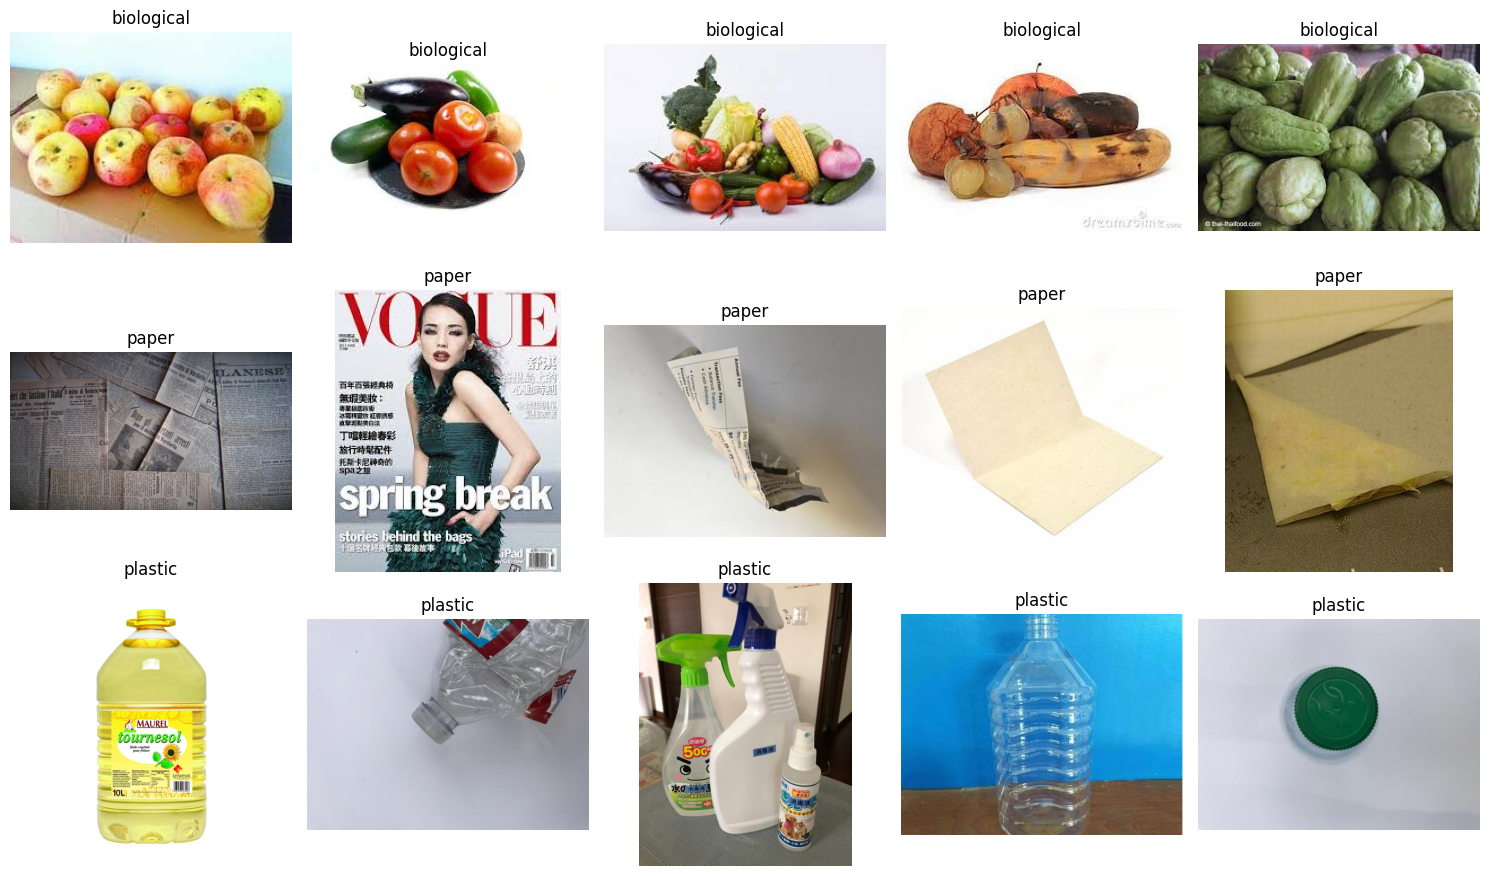

In [7]:
import random
import matplotlib.pyplot as plt
from PIL import Image
import os

classes = ["biological", "paper", "plastic"]

plt.figure(figsize=(15, 9))

for row, class_name in enumerate(classes):
    folder_path = os.path.join(DATASET_DIR, class_name)
    images = os.listdir(folder_path)
    selected_images = random.sample(images, min(5, len(images)))

    for col, filename in enumerate(selected_images):
        image_path = os.path.join(folder_path, filename)

        img = Image.open(image_path).convert("RGB")

        plt.subplot(3, 5, row * 5 + col + 1)
        plt.imshow(img)
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
import os
import shutil
from sklearn.model_selection import train_test_split

# Dataset hasil download Kaggle di Colab
SOURCE_DIR = "/content/garbage_dataset"

# Lokasi penyimpanan permanen di Google Drive
OUTPUT_DIR = "/content/drive/MyDrive/SWMS/dataset_split"

# Mapping nama folder Kaggle ke label model
CLASS_MAPPING = {
    "biological": "organic",
    "paper": "paper",
    "plastic": "plastic"
}

# Persentase split
TRAIN_SIZE = 0.70
VAL_SIZE = 0.15
TEST_SIZE = 0.15

# Supaya pembagian bisa direproduksi
RANDOM_STATE = 42

for original_class, model_class in CLASS_MAPPING.items():
    source_class_dir = os.path.join(SOURCE_DIR, original_class)

    # Ambil file gambar
    images = [
        filename
        for filename in os.listdir(source_class_dir)
        if filename.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    # 70% train, 30% sementara
    train_images, temporary_images = train_test_split(
        images,
        test_size=(1 - TRAIN_SIZE),
        random_state=RANDOM_STATE,
        shuffle=True
    )

    # Bagi 30% sementara menjadi 15% validation dan 15% test
    val_images, test_images = train_test_split(
        temporary_images,
        test_size=0.5,
        random_state=RANDOM_STATE,
        shuffle=True
    )

    split_data = {
        "train": train_images,
        "validation": val_images,
        "test": test_images
    }

    # Buat folder dan salin gambar
    for split_name, filenames in split_data.items():
        destination_dir = os.path.join(
            OUTPUT_DIR,
            split_name,
            model_class
        )

        os.makedirs(destination_dir, exist_ok=True)

        for filename in filenames:
            source_path = os.path.join(source_class_dir, filename)
            destination_path = os.path.join(destination_dir, filename)

            shutil.copy2(source_path, destination_path)

    print(
        f"{model_class}: "
        f"train={len(train_images)}, "
        f"validation={len(val_images)}, "
        f"test={len(test_images)}, "
        f"total={len(images)}"
    )

print("\nSplit dataset selesai!")
print("Dataset tersimpan di:", OUTPUT_DIR)

organic: train=697, validation=150, test=150, total=997
paper: train=1175, validation=252, test=253, total=1680
plastic: train=1388, validation=298, test=298, total=1984

Split dataset selesai!
Dataset tersimpan di: /content/drive/MyDrive/SWMS/dataset_split


In [10]:
for split_name in ["train", "validation", "test"]:
    print(f"\n{split_name.upper()}")

    for class_name in ["organic", "paper", "plastic"]:
        folder_path = os.path.join(
            OUTPUT_DIR,
            split_name,
            class_name
        )

        count = len(os.listdir(folder_path))
        print(f"{class_name}: {count} gambar")


TRAIN
organic: 697 gambar
paper: 1175 gambar
plastic: 1388 gambar

VALIDATION
organic: 150 gambar
paper: 252 gambar
plastic: 298 gambar

TEST
organic: 150 gambar
paper: 253 gambar
plastic: 298 gambar


In [6]:
import os

DATASET_DIR = "/content/drive/MyDrive/SWMS/dataset_split"

for split in ["train", "validation", "test"]:
    print(f"\n{split.upper()}")

    for class_name in ["organic", "paper", "plastic"]:
        folder = os.path.join(DATASET_DIR, split, class_name)
        print(class_name, len(os.listdir(folder)))


TRAIN
organic 697
paper 1175
plastic 1388

VALIDATION
organic 150
paper 252
plastic 298

TEST
organic 150
paper 253
plastic 298


In [5]:
import os

base_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(base_path):
    if os.path.basename(root) == "dataset_split":
        print("Dataset ditemukan:", root)
        print("Isi:", os.listdir(root))

Dataset ditemukan: /content/drive/MyDrive/SWMS/dataset_split
Isi: ['train', 'validation', 'test']


In [7]:
import os

for split in ["train", "validation", "test"]:
    print(f"\n{split.upper()}")

    for class_name in ["organic", "paper", "plastic"]:
        folder = os.path.join(DATASET_DIR, split, class_name)
        print(class_name, "->", os.path.exists(folder))


TRAIN
organic -> True
paper -> True
plastic -> True

VALIDATION
organic -> True
paper -> True
plastic -> True

TEST
organic -> True
paper -> True
plastic -> True


In [8]:
import tensorflow as tf

DATASET_DIR = "/content/drive/MyDrive/SWMS/dataset_split"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATASET_DIR}/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATASET_DIR}/validation",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATASET_DIR}/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Class names:", train_ds.class_names)

Found 3260 files belonging to 3 classes.
Found 700 files belonging to 3 classes.
Found 701 files belonging to 3 classes.
Class names: ['organic', 'paper', 'plastic']


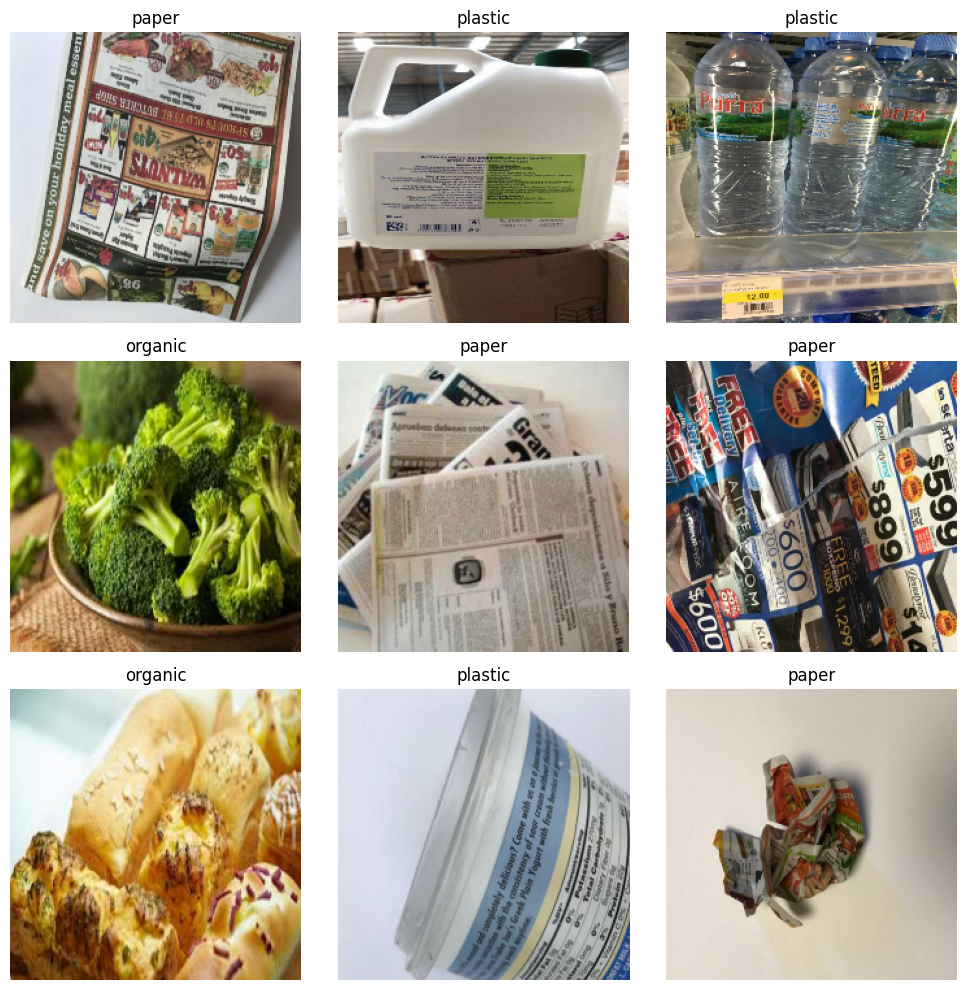

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(train_ds.class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 3
SEED = 42

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [11]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

In [12]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Bekukan base model agar bobot pretrained tidak berubah dulu
base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))

# Preprocessing khusus MobileNetV2
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)

# Ekstraksi fitur dari gambar
x = base_model(x, training=False)

# Ubah feature map menjadi satu vektor
x = layers.GlobalAveragePooling2D()(x)

# Mengurangi risiko overfitting
x = layers.Dropout(0.2)(x)

# Output probabilitas untuk 3 kelas
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [13]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
EPOCHS = 5

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/5
102/102 ━━━━━━━━━━━━━━━━━━━━ 458s 4s/step - accuracy: 0.9089 - loss: 0.2404 - val_accuracy: 0.9771 - val_loss: 0.0861
Epoch 2/5
102/102 ━━━━━━━━━━━━━━━━━━━━ 19s 182ms/step - accuracy: 0.9730 - loss: 0.0857 - val_accuracy: 0.9829 - val_loss: 0.0676
Epoch 3/5
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.9790 - loss: 0.0676

In [1]:
print("History tersedia:", "history" in globals())

if "history" in globals():
    print(history.history)

History tersedia: False


In [2]:
print("Model tersedia:", "model" in globals())

if "model" in globals():
    print("Model berhasil ditemukan")

Model tersedia: False


In [3]:
import tensorflow as tf
import os

print("GPU:", tf.config.list_physical_devices("GPU"))

DATASET_DIR = "/content/drive/MyDrive/SWMS/dataset_split"

print("Dataset tersedia:", os.path.exists(DATASET_DIR))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Dataset tersedia: True


In [4]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATASET_DIR}/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATASET_DIR}/validation",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATASET_DIR}/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(train_ds.class_names)

Found 3260 files belonging to 3 classes.
Found 700 files belonging to 3 classes.
Found 701 files belonging to 3 classes.
['organic', 'paper', 'plastic']


In [5]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import os

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 3
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [6]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))

x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model siap training.")

Model siap training.


In [7]:
MODEL_DIR = "/content/drive/MyDrive/SWMS/models"
os.makedirs(MODEL_DIR, exist_ok=True)

checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath=f"{MODEL_DIR}/swms_mobilenetv2_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

early_stopping_callback = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

In [8]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=[
        checkpoint_callback,
        early_stopping_callback
    ]
)

Epoch 1/3
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.7615 - loss: 0.5410
Epoch 1: val_loss improved from None to 0.09030, saving model to /content/drive/MyDrive/SWMS/models/swms_mobilenetv2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/SWMS/models/swms_mobilenetv2_best.keras
102/102 ━━━━━━━━━━━━━━━━━━━━ 43s 289ms/step - accuracy: 0.8899 - loss: 0.2797 - val_accuracy: 0.9757 - val_loss: 0.0903
Epoch 2/3
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - accuracy: 0.9660 - loss: 0.0982
Epoch 2: val_loss improved from 0.09030 to 0.07435, saving model to /content/drive/MyDrive/SWMS/models/swms_mobilenetv2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/SWMS/models/swms_mobilenetv2_best.keras
102/102 ━━━━━━━━━━━━━━━━━━━━ 19s 164ms/step - accuracy: 0.9678 - loss: 0.0949 - val_accuracy: 0.9743 - val_loss: 0.0743
Epoch 3/3
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.9807 - loss: 0.0687
Epoch 3: val_loss improved from 0.07435 to 0

In [9]:
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

MODEL_PATH = "/content/drive/MyDrive/SWMS/models/swms_mobilenetv2_best.keras"

# Load model terbaik yang tersimpan
best_model = tf.keras.models.load_model(MODEL_PATH)

# Evaluasi pada test set
test_loss, test_accuracy = best_model.evaluate(test_ds)

print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4%}")

22/22 ━━━━━━━━━━━━━━━━━━━━ 116s 5s/step - accuracy: 0.9772 - loss: 0.0800

Test Loss: 0.0800
Test Accuracy: 97.7175%


In [12]:
from sklearn.metrics import classification_report
import numpy as np

class_names = ["organic", "paper", "plastic"]

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob = best_model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 221ms/step
              precision    recall  f1-score   support

     organic     0.9864    0.9667    0.9764       150
       paper     0.9579    0.9881    0.9728       253
     plastic     0.9898    0.9732    0.9814       298

    accuracy                         0.9772       701
   macro avg     0.9780    0.9760    0.9769       701
weighted avg     0.9775    0.9772    0.9772       701



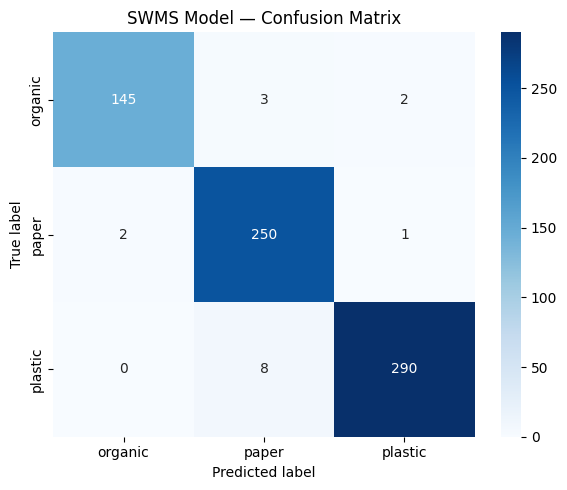

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("SWMS Model — Confusion Matrix")
plt.tight_layout()
plt.show()

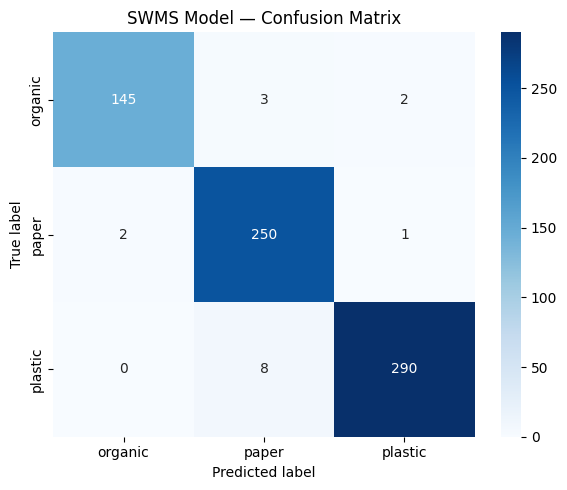

Evaluation artifacts saved to: /content/drive/MyDrive/SWMS/results


In [14]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

# Folder hasil evaluasi
RESULTS_DIR = "/content/drive/MyDrive/SWMS/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

class_names = ["organic", "paper", "plastic"]

# Classification report
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    digits=4
)

with open(f"{RESULTS_DIR}/classification_report.json", "w") as f:
    json.dump(report, f, indent=4)

# Metrik utama
metrics = {
    "test_loss": 0.0800,
    "test_accuracy": 0.9772,
    "test_images": 701,
    "correct_predictions": int(np.sum(y_true == y_pred)),
    "incorrect_predictions": int(np.sum(y_true != y_pred)),
    "classes": class_names
}

with open(f"{RESULTS_DIR}/test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("SWMS Model — Confusion Matrix")
plt.tight_layout()

plt.savefig(
    f"{RESULTS_DIR}/confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("Evaluation artifacts saved to:", RESULTS_DIR)

In [16]:
import tensorflow as tf, numpy as np
for path in ["/content/drive/MyDrive/SWMS/dataset_split/test/organic/biological_102.jpg", "/content/drive/MyDrive/SWMS/dataset_split/test/paper/paper_1000.jpg", "/content/drive/MyDrive/SWMS/dataset_split/test/plastic/plastic_101.jpg"]:
    ds = tf.keras.utils.load_img(path)
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (224, 224))
    p = model.predict(tf.expand_dims(img, 0), verbose=0)[0]
    print(path, np.round(p, 4))

/content/drive/MyDrive/SWMS/dataset_split/test/organic/biological_102.jpg [9.978e-01 1.700e-03 4.000e-04]
/content/drive/MyDrive/SWMS/dataset_split/test/paper/paper_1000.jpg [1.000e-04 9.997e-01 2.000e-04]
/content/drive/MyDrive/SWMS/dataset_split/test/plastic/plastic_101.jpg [1.000e-03 7.000e-04 9.983e-01]


In [17]:
from google.colab import files
base = "/content/drive/MyDrive/SWMS/dataset_split/test"
for p in ["organic/biological_102.jpg", "paper/paper_1000.jpg", "plastic/plastic_101.jpg"]:
    files.download(f"{base}/{p}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Found 701 files belonging to 3 classes.
Test accuracy: 0.9772, loss: 0.0800


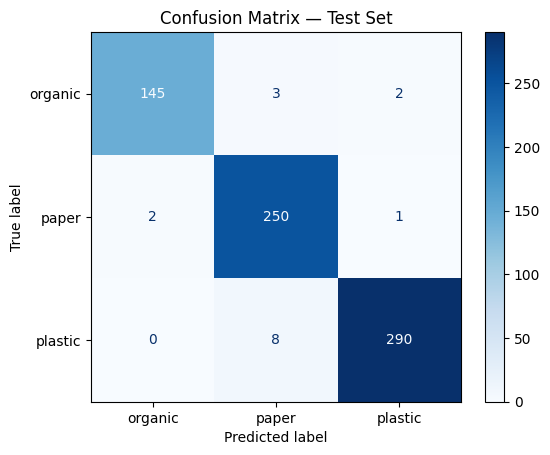

In [21]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

BASE = "/content/drive/MyDrive/SWMS"
OUT_METRICS = f"{BASE}/results/metrics"
OUT_FIGURES = f"{BASE}/results/figures"
os.makedirs(OUT_METRICS, exist_ok=True)
os.makedirs(OUT_FIGURES, exist_ok=True)

# Load test set (shuffle=False supaya urutan label cocok dengan prediksi)
test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{BASE}/dataset_split/test", image_size=(224, 224), batch_size=32, shuffle=False
)
class_names = test_ds.class_names
model = keras.models.load_model(f"{BASE}/models/swms_mobilenetv2_best.keras")

# Evaluasi
loss, acc = model.evaluate(test_ds, verbose=0)
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)
print(f"Test accuracy: {acc:.4f}, loss: {loss:.4f}")  # harus ~0.9772 dan ~0.0800

# 1. Ringkasan metrik
with open(f"{OUT_METRICS}/test_metrics.json", "w") as f:
    json.dump({"test_loss": round(loss, 4), "test_accuracy": round(acc, 4),
               "test_images": int(len(y_true)), "classes": class_names}, f, indent=2)

# 2. Classification report
report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True, digits=4)
with open(f"{OUT_METRICS}/classification_report.json", "w") as f:
    json.dump(report, f, indent=2)

# 3. Confusion matrix (CSV + gambar)
cm = confusion_matrix(y_true, y_pred)
pd.DataFrame(cm, index=[f"true_{c}" for c in class_names],
             columns=[f"pred_{c}" for c in class_names]).to_csv(f"{OUT_METRICS}/confusion_matrix.csv")

ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Test Set")
plt.savefig(f"{OUT_FIGURES}/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

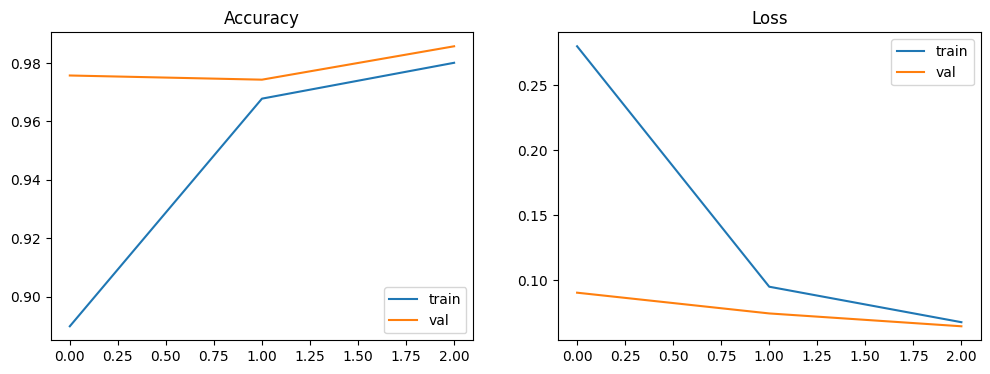

In [22]:
h = history.history
pd.DataFrame(h).to_csv(f"{OUT_METRICS}/training_history.csv", index_label="epoch")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["accuracy"], label="train"); ax[0].plot(h["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(h["loss"], label="train"); ax[1].plot(h["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].legend()
plt.savefig(f"{OUT_FIGURES}/training_curves.png", dpi=150, bbox_inches="tight")
plt.show()